In [1]:
# 作业2：Explore a netCDF dataset

# 数据读入和预处理
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

# 读取数据时根据官方文档跳过有异常填充值的辅助变量time_bnds
ds = xr.open_dataset("precip.mon.mean.nc", drop_variables="time_bnds")
precip = ds["precip"].sel(time=slice("1991", "2020")).load()
ds.close()

# 将经度从0～360°转换到-180～180°，方便绘制全球图
precip = precip.assign_coords(lon=(precip.lon + 180) % 360 - 180)
precip = precip.sortby("lon").sortby("lat")

# 从每年选出六月，共得到30个六月，沿时间平均后，rain只剩纬度和经度两个维度
june = precip.where(precip.time.dt.month == 6, drop=True)
rain = june.mean(dim="time")

# 深圳的位置
sz_lon, sz_lat = 114.05, 22.55
# 找到离深圳代表位置最近的格点中心。
cell = rain.sel(lon=sz_lon, lat=sz_lat, method="nearest")
grid_lon = float(cell.lon)
grid_lat = float(cell.lat)
grid_value = float(cell)
# 计算包含深圳网格的中心和边界坐标数据
dx = float(rain.lon[1] - rain.lon[0])
dy = float(rain.lat[1] - rain.lat[0])
west, east = grid_lon - dx / 2, grid_lon + dx / 2
south, north = grid_lat - dy / 2, grid_lat + dy / 2

print("参与平均的六月数量：", june.sizes["time"])
print("所在格点中心（经度、纬度）：", grid_lon, grid_lat)
print("所在格点经度范围：", west, "～", east)
print("所在格点纬度范围：", south, "～", north)
print(f"所在格点六月平均降水率：{grid_value:.3f} mm/day")

data_crs = ccrs.PlateCarree()

参与平均的六月数量： 30
所在格点中心（经度、纬度）： 113.75 23.75
所在格点经度范围： 112.5 ～ 115.0
所在格点纬度范围： 22.5 ～ 25.0
所在格点六月平均降水率：12.016 mm/day


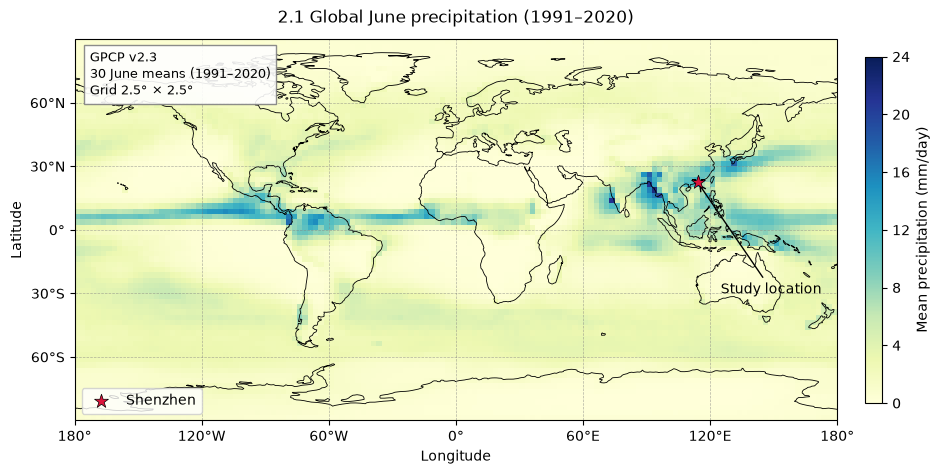

In [4]:
# 题目2.1：绘制1991—2020年六月平均降水率的全球地图

# 创建地图，使用PlateCarree投影
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_global()

# 绘制降水填色图（两张地图都使用0～24mm/day的色标，便于直接比较颜色）
im = ax.pcolormesh(rain.lon, rain.lat, rain,transform=data_crs,shading="auto",cmap="YlGnBu",vmin=0,vmax=24)

# 使用海岸线作为满足题目中“masks or features”的地理要素要求的内容
ax.coastlines(resolution="110m", linewidth=0.6)

# 设置经纬度刻度
xticks = np.arange(-180, 181, 60)
yticks = np.arange(-60, 61, 30)
ax.set_xticks(xticks, crs=data_crs)
ax.set_yticks(yticks, crs=data_crs)
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

# 添加与刻度位置对应的经纬网格线
ax.gridlines( xlocs=xticks, ylocs=yticks,linewidth=0.5, color="gray", linestyle="--",alpha=0.6)

# 标记深圳的位置，label用于生成图例
ax.scatter(
    sz_lon, sz_lat,
    marker="*", s=110, color="crimson",
    edgecolors="black", linewidths=0.5,
    transform=data_crs, zorder=5,
    label="Shenzhen"
)
ax.legend(loc="lower left")

# 添加箭头标注，xy是箭头指向的位置，xytext是文字的位置
ax.annotate(
    "Study location",
    xy=(sz_lon, sz_lat),
    xytext=(125, -30),
    transform=data_crs,
    arrowprops={"arrowstyle": "->", "color": "black"},
    fontsize=10
)
# 添加文本框
ax.text(
    0.02, 0.97,
    "GPCP v2.3\n30 June means (1991–2020)\nGrid 2.5° × 2.5°",
    transform=ax.transAxes,
    va="top", fontsize=9,
    bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "gray"}
)
# 添加图名标题
ax.set_title("2.1 Global June precipitation (1991–2020)", pad=12)

# 色标解释填色数值，图例解释星号符号
cbar = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.03)
cbar.set_label("Mean precipitation (mm/day)")
cbar.set_ticks(np.arange(0, 25, 4))

plt.show()

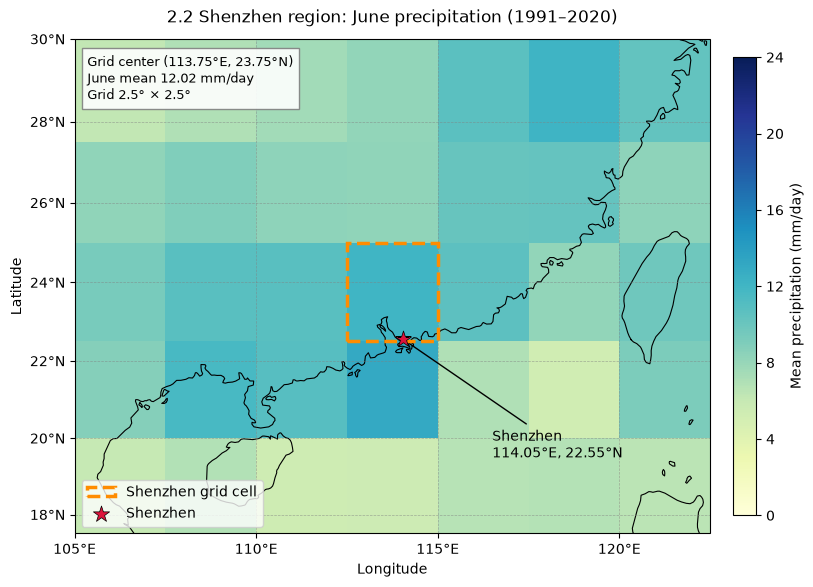

In [5]:
# 题目2.2：绘制1991—2020年六月平均降水率的区域地图（包含深圳）

# 从同一张六月平均降水图中选取深圳及周边区域
regional = rain.sel(lon=slice(105, 122.5),lat=slice(17.5, 30))
# 使用与全球图不同的Mercator投影
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Mercator())
# 顺序为西边界、东边界、南边界、北边界
ax.set_extent([105, 122.5, 17.5, 30], crs=data_crs)
im = ax.pcolormesh(
    regional.lon, regional.lat, regional,
    transform=data_crs,
    shading="auto",
    cmap="YlGnBu",
    vmin=0, vmax=24
)

# 区域图使用更精细的海岸线地理要素
ax.coastlines(resolution="50m", linewidth=0.8)

# 设置横纵轴标签、刻度和网格线
xticks = np.arange(105, 123, 5)
yticks = np.arange(18, 31, 2)
ax.set_xticks(xticks, crs=data_crs)
ax.set_yticks(yticks, crs=data_crs)
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.gridlines(
    xlocs=xticks, ylocs=yticks,
    linewidth=0.5, color="gray", linestyle="--", alpha=0.6
)
# 用矩形圈出包含深圳的网格
box = Rectangle(
    (west, south), dx, dy,
    fill=False,
    edgecolor="darkorange",
    linewidth=2.5,
    linestyle="--",
    transform=data_crs,
    zorder=5,
    label="Shenzhen grid cell"
)
ax.add_patch(box)

# 标出深圳的市中心位置
ax.scatter(
    sz_lon, sz_lat,
    marker="*", s=150, color="crimson",
    edgecolors="black", linewidths=0.5,
    transform=data_crs, zorder=6,
    label="Shenzhen"
)
ax.legend(loc="lower left")

# 添加箭头和位置说明
ax.annotate(
    "Shenzhen\n114.05°E, 22.55°N",
    xy=(sz_lon, sz_lat),
    xytext=(116.5, 19.5),
    transform=data_crs,
    arrowprops={"arrowstyle": "->", "color": "black"},
    fontsize=10
)
# 文本框展示所选格点的中心坐标和降水值
ax.text(
    0.02, 0.97,
    f"Grid center ({grid_lon:.2f}°E, {grid_lat:.2f}°N)\n"
    f"June mean {grid_value:.2f} mm/day\nGrid 2.5° × 2.5°",
    transform=ax.transAxes,
    va="top", fontsize=9,
    bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "gray"}
)
# 添加图名标题
ax.set_title("2.2 Shenzhen region: June precipitation (1991–2020)",pad=12)
# 设置色标和图例，同题目2.1一致
cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.03)
cbar.set_label("Mean precipitation (mm/day)")
cbar.set_ticks(np.arange(0, 25, 4))

plt.show()